<img src="https://webna.ir/wp-content/uploads/2018/08/%D9%85%DA%A9%D8%AA%D8%A8-%D8%AE%D9%88%D9%86%D9%87.png" width=50% />

<div class="alert alert-block alert-success">
    <h1 align="center">Machine Learning in Python</h1>
    <h3 align="center">Bike Sharing</h3>
</div>

<img src = "https://storage.googleapis.com/kaggle-competitions/kaggle/3948/media/bikes.png" width=80%>

## Importing the libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor 
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
from sklearn.model_selection import GridSearchCV


## Load and Prepare Data

In [2]:
df = pd.read_csv('../data/train.csv')
df.head(10)

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0000,3,13,16
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0000,8,32,40
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0000,5,27,32
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0000,3,10,13
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0000,0,1,1
5,2011-01-01 05:00:00,1,0,0,2,9.84,12.880,75,6.0032,0,1,1
6,2011-01-01 06:00:00,1,0,0,1,9.02,13.635,80,0.0000,2,0,2
7,2011-01-01 07:00:00,1,0,0,1,8.20,12.880,86,0.0000,1,2,3
8,2011-01-01 08:00:00,1,0,0,1,9.84,14.395,75,0.0000,1,7,8
9,2011-01-01 09:00:00,1,0,0,1,13.12,17.425,76,0.0000,8,6,14


## EDA

In [3]:
print("Shape: ",df.shape)
print()
df.info()

Shape:  (10886, 12)

<class 'pandas.DataFrame'>
RangeIndex: 10886 entries, 0 to 10885
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   datetime    10886 non-null  str    
 1   season      10886 non-null  int64  
 2   holiday     10886 non-null  int64  
 3   workingday  10886 non-null  int64  
 4   weather     10886 non-null  int64  
 5   temp        10886 non-null  float64
 6   atemp       10886 non-null  float64
 7   humidity    10886 non-null  int64  
 8   windspeed   10886 non-null  float64
 9   casual      10886 non-null  int64  
 10  registered  10886 non-null  int64  
 11  count       10886 non-null  int64  
dtypes: float64(3), int64(8), str(1)
memory usage: 1020.7 KB


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
season,10886.0,2.506614,1.116174,1.00,2.0000,3.000,4.0000,4.0000
holiday,10886.0,0.028569,0.166599,0.00,0.0000,0.000,0.0000,1.0000
workingday,10886.0,0.680875,0.466159,0.00,0.0000,1.000,1.0000,1.0000
weather,10886.0,1.418427,0.633839,1.00,1.0000,1.000,2.0000,4.0000
temp,10886.0,20.230860,7.791590,0.82,13.9400,20.500,26.2400,41.0000
atemp,10886.0,23.655084,8.474601,0.76,16.6650,24.240,31.0600,45.4550
humidity,10886.0,61.886460,19.245033,0.00,47.0000,62.000,77.0000,100.0000
windspeed,10886.0,12.799395,8.164537,0.00,7.0015,12.998,16.9979,56.9969
casual,10886.0,36.021955,49.960477,0.00,4.0000,17.000,49.0000,367.0000
registered,10886.0,155.552177,151.039033,0.00,36.0000,118.000,222.0000,886.0000


In [5]:
print("Missing value:")
print(df.isnull().sum())
print("Duplicates rows: ", df.duplicated().sum())

Missing value:
datetime      0
season        0
holiday       0
workingday    0
weather       0
temp          0
atemp         0
humidity      0
windspeed     0
casual        0
registered    0
count         0
dtype: int64
Duplicates rows:  0


In [6]:
(df['casual'] + df['registered'] == df['count'].all())

0        False
1        False
2        False
3        False
4         True
         ...  
10881    False
10882    False
10883    False
10884    False
10885    False
Length: 10886, dtype: bool

In [7]:
for col in ['season' , 'holiday' , 'workingday' , 'weather']:
    print(col , "->" , sorted(df[col].unique()))

season -> [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
holiday -> [np.int64(0), np.int64(1)]
workingday -> [np.int64(0), np.int64(1)]
weather -> [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


In [8]:
# بررسی تعداد رکوردهای هر دسته‌ی آب‌وهوا و فصل

print("Weather counts:")
print(df['weather'].value_counts().sort_index())
print()
print("Season counts:")
print(df['season'].value_counts().sort_index())

Weather counts:
weather
1    7192
2    2834
3     859
4       1
Name: count, dtype: int64

Season counts:
season
1    2686
2    2733
3    2733
4    2734
Name: count, dtype: int64


## Data Preprocessing


In [9]:
# datetime
df['datetime'] = pd.to_datetime(df['datetime'])
df['year'] = df['datetime'].dt.year
df['month'] = df['datetime'].dt.month
df['day'] = df['datetime'].dt.day
df['hour'] = df['datetime'].dt.hour
df['dayofweek'] = df['datetime'].dt.dayofweek
df = df.drop(columns=['datetime'])


In [10]:
df['weather'] = df['weather'].replace({4: 3})

In [11]:
df = df.drop(columns=['casual','registered'])

In [12]:
df = pd.get_dummies(df , columns=['season' , 'weather'] , drop_first=False)

In [13]:
bool_cols = df.select_dtypes(include='bool').columns


df[bool_cols] = df[bool_cols].astype(int)

#df.head()

In [14]:
# Split
x = df.drop(columns=['count'])
y = df['count']
print(x.shape)
print(y.shape)
#print("\n",x.columns.tolist())


(10886, 18)
(10886,)


In [15]:
x_train , x_val , y_train , y_val = train_test_split(
    x,y,
    test_size=0.2 ,
    random_state=42
)
print("X_t :",x_train.shape , "Y_t" , y_train.shape)
print("X_v :",x_val.shape , "Y_v" , y_val.shape)

X_t : (8708, 18) Y_t (8708,)
X_v : (2178, 18) Y_v (2178,)


In [16]:
#scaling
scaler = StandardScaler()
scaler.fit(x_train)
print(len(scaler.mean_))

18


In [17]:
x_train_scaled = scaler.transform(x_train)
x_val_scaled = scaler.transform(x_val)

print(x_train_scaled.shape)
print(x_val_scaled.shape)

(8708, 18)
(2178, 18)


In [18]:
print(np.round(x_train_scaled.mean(axis=0), 3))
print()
print(np.round(x_train_scaled.std(axis=0), 3))

[ 0.  0.  0. -0.  0.  0. -0. -0.  0. -0.  0.  0.  0.  0.  0. -0.  0. -0.]

[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## _______________________________________________________________________________________________________________________________________________

## Strorytelling - Visualization

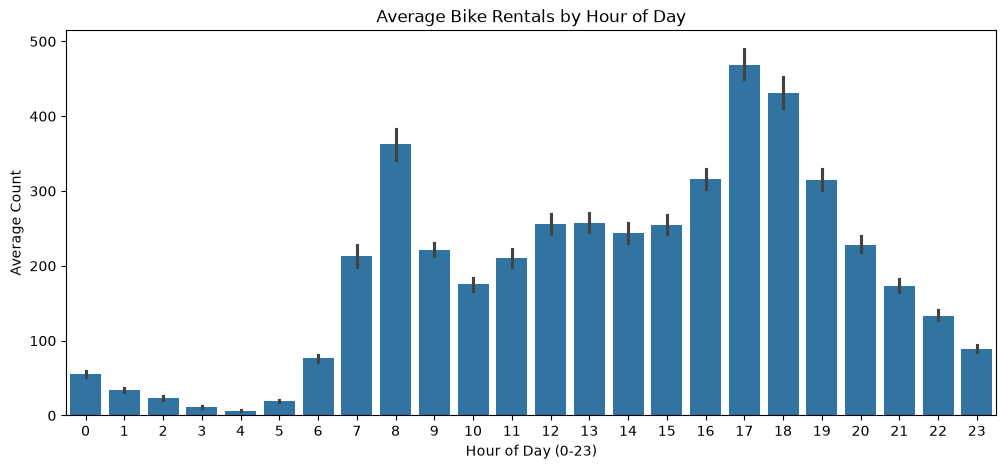

In [19]:
# میانگین تعداد اجاره‌ها در هر ساعت از شبانه‌روز
plt.figure(figsize=(12, 5))
sns.barplot(x='hour', y='count', data=df)
plt.title("Average Bike Rentals by Hour of Day")
plt.xlabel("Hour of Day (0-23)")
plt.ylabel("Average Count")
plt.show()

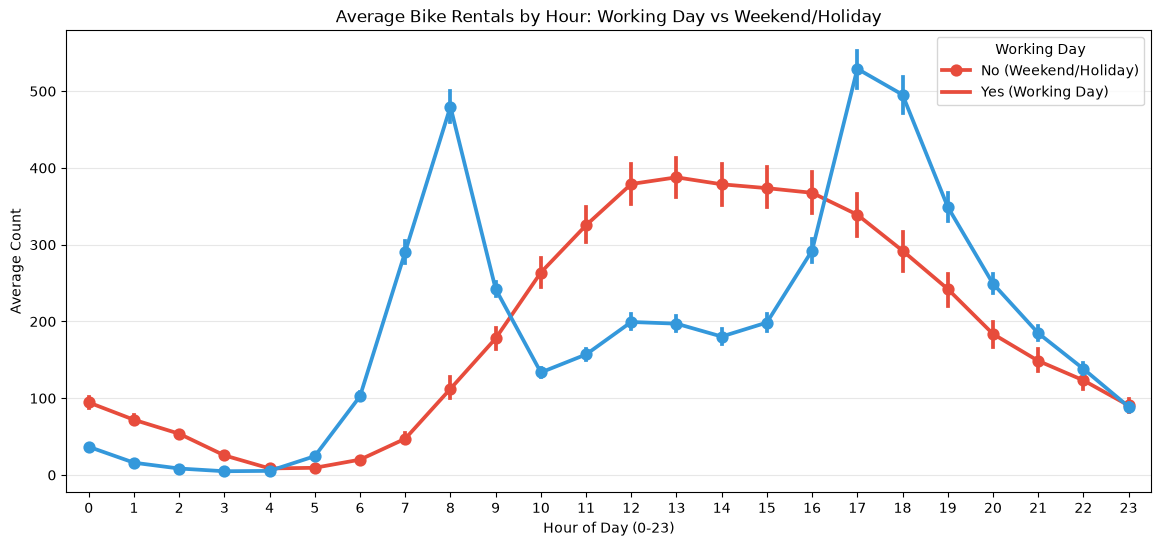

In [20]:
# مقایسه‌ی الگوی ساعتی در روزهای کاری و غیرکاری
plt.figure(figsize=(14, 6))
sns.pointplot(x='hour', y='count', hue='workingday', data=df,
              palette={0: '#e74c3c', 1: '#3498db'})
plt.title("Average Bike Rentals by Hour: Working Day vs Weekend/Holiday")
plt.xlabel("Hour of Day (0-23)")
plt.ylabel("Average Count")
plt.legend(title='Working Day', labels=['No (Weekend/Holiday)', 'Yes (Working Day)'])
plt.grid(axis='y', alpha=0.3)
plt.show()

ValueError: Could not interpret value `season` for `x`. An entry with this name does not appear in `data`.

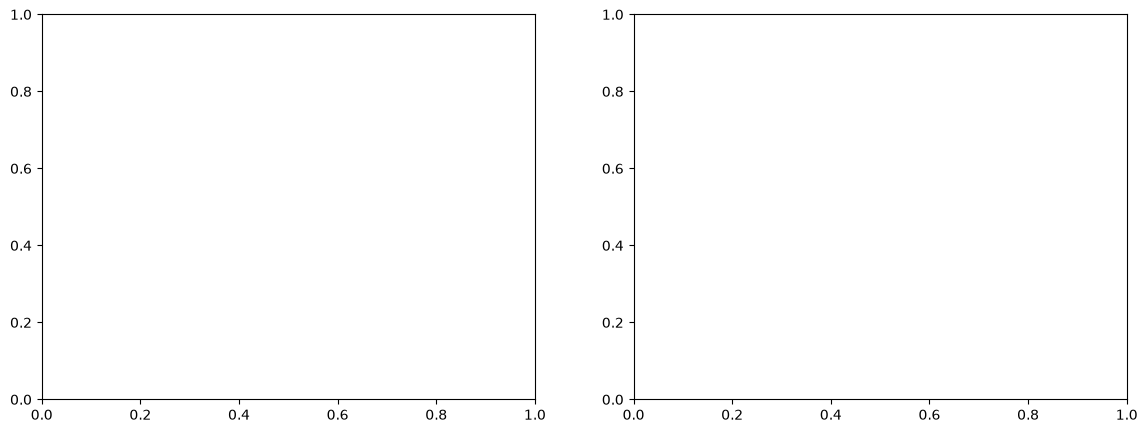

In [21]:
# --- فصل و آب‌وهوا ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# نمودار فصل
sns.boxplot(x='season', y='count', data=df, ax=axes[0])
axes[0].set_title("Bike Rentals by Season")
axes[0].set_xticklabels(['Spring', 'Summer', 'Fall', 'Winter'])
axes[0].set_xlabel("Season")
axes[0].set_ylabel("Count")

# نمودار آب‌وهوا
sns.boxplot(x='weather', y='count', data=df, ax=axes[1])
axes[1].set_title("Bike Rentals by Weather")
axes[1].set_xticklabels(['Clear', 'Mist/Cloudy', 'Light Rain/Snow', 'Heavy Rain/Snow'])
axes[1].set_xlabel("Weather")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()

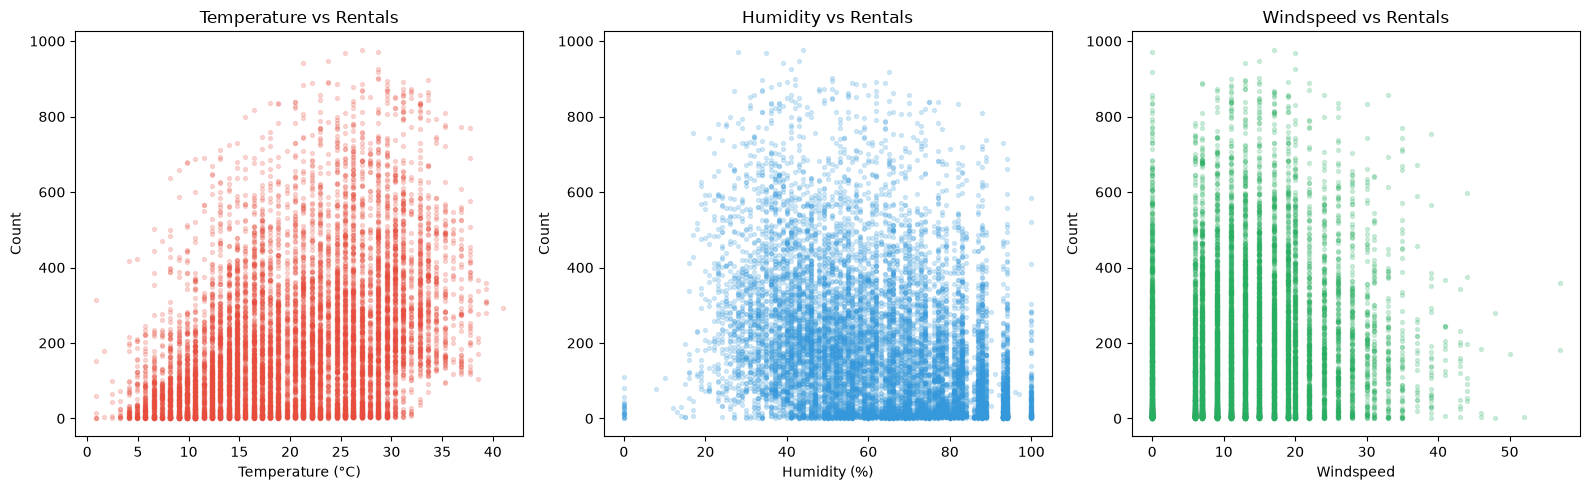

In [22]:
# --- فیچرهای عددی vs target ---
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# temp vs count
axes[0].scatter(df['temp'], df['count'], alpha=0.2, s=8, color='#e74c3c')
axes[0].set_title("Temperature vs Rentals")
axes[0].set_xlabel("Temperature (°C)")
axes[0].set_ylabel("Count")

# humidity vs count
axes[1].scatter(df['humidity'], df['count'], alpha=0.2, s=8, color='#3498db')
axes[1].set_title("Humidity vs Rentals")
axes[1].set_xlabel("Humidity (%)")
axes[1].set_ylabel("Count")

# windspeed vs count
axes[2].scatter(df['windspeed'], df['count'], alpha=0.2, s=8, color='#27ae60')
axes[2].set_title("Windspeed vs Rentals")
axes[2].set_xlabel("Windspeed")
axes[2].set_ylabel("Count")

plt.tight_layout()
plt.show()

In [23]:
# --- روند تعداد اجاره‌ها در طول زمان ---
plt.figure(figsize=(14, 5))
plt.plot(df['datetime'], df['count'], linewidth=0.3, color='#2c3e50')
plt.title("Bike Rentals Over Time")
plt.xlabel("Date")
plt.ylabel("Count")
plt.grid(alpha=0.3)
plt.show()

KeyError: 'datetime'

<Figure size 1400x500 with 0 Axes>

## Train your model (Regression/Regressor)

In [24]:
LR = LinearRegression()
LR.fit(x_train_scaled , y_train)
y_pred_LR = LR.predict(x_val_scaled)

In [21]:
KNN = KNeighborsRegressor(n_neighbors=5,algorithm='brute',n_jobs=-1)
KNN.fit(x_train_scaled,y_train)
y_pred_KNN = KNN.predict(x_val_scaled)

In [22]:
# KNN GSC
# از این کتابخونه جی اس سی استفادهکردم که میشه به یک باره باهاش چندین پارامتر مختلف چک میشه و بهترین رو انتخاب میکنه دیگخ نیاز نیست دستی چندین بار تست کنیم
from sklearn.model_selection import GridSearchCV

param_grid_knn = {
    'n_neighbors': [3, 5, 7, 10, 15, 20, 30],
    'weights': ['uniform', 'distance']
}

grid_knn = GridSearchCV(
    KNeighborsRegressor(algorithm='brute', n_jobs=-1),
    param_grid_knn,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

grid_knn.fit(x_train_scaled, y_train)

print("Best KNN params:", grid_knn.best_params_)
print("Best KNN CV R²:", grid_knn.best_score_)
# خب زیاد بهبود پیدانکرد و بهتره  همینجور بزاریمش کنار بقیه مدلا
# دلایش میتونه دیتای نویزی یا ابعاد بالا باشه چون 18 فیچر میشه 18 بعد و در 18 بعد با بعضی فیچرای نویزی و الگوری پیچیده بعضی فیچرا باشه
# فعلا همون چنگل تصادفی بهتریم عملکردو داشته
# ولی بریم سراغ نهایی کردنش و ببینم بهتر از سری قبل شده یا نه پون ما تا اینحا آردو رو دیدیم فقط

Best KNN params: {'n_neighbors': 7, 'weights': 'distance'}
Best KNN CV R²: 0.5653007031622976


In [23]:
# KNN tuning
KNN_tuned = KNeighborsRegressor(
    n_neighbors=7,
    weights='distance',
    algorithm='brute',
    n_jobs=-1
)
KNN_tuned.fit(x_train_scaled, y_train)
y_pred_KNN_tuned = KNN_tuned.predict(x_val_scaled)

In [24]:
DT = DecisionTreeRegressor(random_state=42)
DT.fit(x_train , y_train)
y_pred_DT = DT.predict(x_val)

In [25]:
# DT tuninig
depths = [2, 3, 5, 7, 10, 15, 20]
results_dt = []

for d in depths:
    dt = DecisionTreeRegressor(max_depth=d, random_state=42)
    dt.fit(x_train, y_train)
    
    r2_train = r2_score(y_train, dt.predict(x_train))
    r2_val   = r2_score(y_val, dt.predict(x_val))
    
    results_dt.append({
        'max_depth': d,
        'Train R²': round(r2_train, 4),
        'Val R²':   round(r2_val, 4),
        'Gap':      round(r2_train - r2_val, 4)
    })

df_dt = pd.DataFrame(results_dt)
print(df_dt.to_string(index=False))
# max depth = 10 is best

 max_depth  Train R²  Val R²     Gap
         2    0.4042  0.4054 -0.0012
         3    0.5016  0.5114 -0.0098
         5    0.6454  0.6516 -0.0062
         7    0.7684  0.7792 -0.0108
        10    0.9361  0.8958  0.0402
        15    0.9927  0.9079  0.0848
        20    0.9996  0.9058  0.0938


In [26]:
#  DT : max_depth=10 
DT_tuned = DecisionTreeRegressor(max_depth=10, random_state=42)
DT_tuned.fit(x_train, y_train)
y_pred_DT_tuned = DT_tuned.predict(x_val)



In [27]:
RF = RandomForestRegressor(
    n_estimators = 100,
    random_state = 42,
    n_jobs=-1
)
RF.fit(x_train , y_train)
y_pred_RF = RF.predict(x_val)

In [28]:
param_grid_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [10, 15, 20, None],
    'min_samples_split': [2, 5, 10]
}

grid_rf = GridSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    param_grid_rf,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

grid_rf.fit(x_train, y_train)

print("Best RF params:", grid_rf.best_params_)
print("Best RF CV R²:", grid_rf.best_score_)

Best RF params: {'max_depth': 20, 'min_samples_split': 2, 'n_estimators': 200}
Best RF CV R²: 0.9466082169429647


In [29]:
# RF tuning
RF_tuned = RandomForestRegressor(
    n_estimators=200,
    max_depth=20,
    min_samples_split=2,
    random_state=42,
    n_jobs=-1
)
RF_tuned.fit(x_train, y_train)
y_pred_RF_tuned = RF_tuned.predict(x_val)


## __________________________________________________________________________________________________

## Test Result

In [30]:
MAE = mean_absolute_error(y_val,y_pred_LR)
RMSE = np.sqrt(mean_squared_error(y_val,y_pred_LR))
R2 = r2_score(y_val , y_pred_LR)
print('MAE: ' , MAE)
print('RMSE: ' , RMSE)
print('R2: ' , R2)
# بهبودش نمیدم چون بفیه الگوریتما عملکرد بهتری دارن پس نیاز نیست وقتمو بزارم برای بهبود عملکرد رگرسیون ساده

MAE:  105.0892080401269
RMSE:  140.6319157081921
R2:  0.4008127323110381


In [31]:
MAE_KNN = mean_absolute_error(y_val , y_pred_KNN)
RMSE_KNN = np.sqrt(mean_squared_error(y_val , y_pred_KNN))
R2_KNN = r2_score(y_val , y_pred_KNN)
print("KNN regressor (k=5)")
print(f"MAE_KNN: {MAE_KNN:.2f}")
print(f"RMSE_KNN: {RMSE_KNN:.2f}")
print(f"R2_KNN: {R2_KNN:.2f}")

KNN regressor (k=5)
MAE_KNN: 82.43
RMSE_KNN: 121.57
R2_KNN: 0.55


In [32]:
MAE_KNN_tuned  = mean_absolute_error(y_val, y_pred_KNN_tuned)
RMSE_KNN_tuned = np.sqrt(mean_squared_error(y_val, y_pred_KNN_tuned))
R2_KNN_tuned   = r2_score(y_val, y_pred_KNN_tuned)

print("KNN Tuned (k=7, distance):")
print(f"  MAE : {MAE_KNN_tuned:.2f}")
print(f"  RMSE: {RMSE_KNN_tuned:.2f}")
print(f"  R²  : {R2_KNN_tuned:.4f}")
# و بعله از مدت قبلی بهتر شد و ارز داره اینو به جای حالت پایه استفاده کنیم چون عملکرد بهتری داره
# دلیل تفاوت آردو در مرحله قبل و اینجا اینه که اوتجا مبانگین 5 فولد مختلف گزارش داده میشد 
#فولد ولیدیشن ما که تصادفی از ترین جدا شده و شانسی راحتر از میانگین بوده
#پس سی وی واقعبینانه تره و ولیدیشن ما شانسی تر بوده
# منظوز از شانسی اینه که اسپلیتی که با رندوم استیت 42 ساختیم راحتر از میانگین بوده
# شانسی نبوده در واقع جی سی وی واقها بهترین پارامترو پیداکرده و کی ان ان بهتر شده
# موقع پرازش باید آردو0.5653 گزارش داه یشه چون واقع بینانست میانگین پنج حالت مختلف نه یه شانس خوب
# در واقع جون ولیدیشن تصادفی انتخاب شده یعنی شانسمون خوب بوده


KNN Tuned (k=7, distance):
  MAE : 76.38
  RMSE: 112.87
  R²  : 0.6140


In [33]:
MAE_DT = mean_absolute_error(y_val,y_pred_DT)
RMSE_DT = np.sqrt(mean_squared_error(y_val , y_pred_DT))
R2_DT = r2_score(y_val , y_pred_DT)
print(f"MAE_DT: {MAE_DT:.2f}")
print(f"RMSE_DT: {RMSE_DT:.2f}")
print(f"R2_DT: {R2_DT:.2f}")

MAE_DT: 33.38
RMSE_DT: 57.59
R2_DT: 0.90


In [34]:
MAE_DT_tuned  = mean_absolute_error(y_val, y_pred_DT_tuned)
RMSE_DT_tuned = np.sqrt(mean_squared_error(y_val, y_pred_DT_tuned))
R2_DT_tuned   = r2_score(y_val, y_pred_DT_tuned)

print("Decision Tree (max_depth=10):")
print(f"  MAE : {MAE_DT_tuned:.2f}")
print(f"  RMSE: {RMSE_DT_tuned:.2f}")
print(f"  R²  : {R2_DT_tuned:.4f}")
# خب عمق 10 مدل رو ضعیفتر کرد پس تیونینگ برای دیسیژن تری فقط بدترش کرد
# ارزش جنگل تصادفی بالاتره چون در جالت پایش از جالت پایه و بهبود یافته این بهتر بوده
# نتیجه : تیون همیشه بهترین کار نیست

Decision Tree (max_depth=10):
  MAE : 35.35
  RMSE: 58.64
  R²  : 0.8958


In [35]:
MAE_RF = mean_absolute_error(y_val,y_pred_RF)
RMSE_RF = np.sqrt(mean_squared_error(y_val , y_pred_RF))
R2_RF = r2_score(y_val , y_pred_RF)
print(f"MAE_RF: {MAE_RF:.2f}")
print(f"RMSE_RF: {RMSE_RF:.2f}")
print(f"R2_RF: {R2_RF:.2f}")

MAE_RF: 24.28
RMSE_RF: 38.81
R2_RF: 0.95


In [36]:
MAE_RF_tuned  = mean_absolute_error(y_val, y_pred_RF_tuned)
RMSE_RF_tuned = np.sqrt(mean_squared_error(y_val, y_pred_RF_tuned))
R2_RF_tuned   = r2_score(y_val, y_pred_RF_tuned)

print("Random Forest Tuned:")
print(f"  MAE : {MAE_RF_tuned:.2f}")
print(f"  RMSE: {RMSE_RF_tuned:.2f}")
print(f"  R²  : {R2_RF_tuned:.4f}")
# خب بهبودی نداشتیم پون رندوم فارست خودش ذاتا مدل قوییه و پارامترای پیش فرض ار قبل خوب بودن
# پس گرید سرچ عملا بی فایده بوده و 36 ترکیب مختلف هیچکدوم بهتر از پیش فرض نبود
# درسته آردو یه چیز دیگه شد ولی با آردویی که داشتیم تقریبا یکی بود تفاوتشون ناچیزه
# و میتونه دلیلش اینم باشه که به سقف دیتا رسیدیم و بقیه خطاها نویز داتی دیتاها و فیچرا هستن
# پس همیشه تیونینگ بهتر نیست ولی انحام میشه که شاید بهتر باشه و تازه سی وی برای گزارشم بهمون میده
# ما همینو نگه میداریم چون یکمم بهتر شده

Random Forest Tuned:
  MAE : 24.27
  RMSE: 38.79
  R²  : 0.9544


In [37]:
# check all models

# --- Train predictions ---
y_train_pred_LR  = LR.predict(x_train_scaled)
y_train_pred_KNN = KNN.predict(x_train_scaled)
y_train_pred_DT  = DT.predict(x_train)
y_train_pred_RF  = RF.predict(x_train)

# --- Train R² ---
R2_train_LR  = r2_score(y_train, y_train_pred_LR)
R2_train_KNN = r2_score(y_train, y_train_pred_KNN)
R2_train_DT  = r2_score(y_train, y_train_pred_DT)
R2_train_RF  = r2_score(y_train, y_train_pred_RF)

# --- جدول Overfitting ---
overfit_check = pd.DataFrame({
    'Model':      ['Linear', 'KNN', 'Decision Tree', 'Random Forest'],
    'Train R²':   [R2_train_LR, R2_train_KNN, R2_train_DT, R2_train_RF],
    'Val R²':     [R2, R2_KNN, R2_DT, R2_RF],
    'Gap (Train-Val)': [R2_train_LR - R2, R2_train_KNN - R2_KNN, R2_train_DT - R2_DT, R2_train_RF - R2_RF]
})

print(overfit_check.to_string(index=False))

        Model  Train R²   Val R²  Gap (Train-Val)
       Linear  0.396337 0.400813        -0.004476
          KNN  0.711106 0.552263         0.158843
Decision Tree  1.000000 0.899524         0.100476
Random Forest  0.992818 0.954361         0.038457


In [38]:
# ==============================
# Cross Validation
# ==============================
from sklearn.model_selection import cross_val_score

cv_scores_LR  = cross_val_score(LR,        x_train_scaled, y_train, cv=5, scoring='r2', n_jobs=-1)
cv_scores_KNN = cross_val_score(KNN_tuned, x_train_scaled, y_train, cv=5, scoring='r2', n_jobs=-1)
cv_scores_DT  = cross_val_score(DT_tuned,  x_train,        y_train, cv=5, scoring='r2', n_jobs=-1)
cv_scores_RF  = cross_val_score(RF_tuned,  x_train,        y_train, cv=5, scoring='r2', n_jobs=-1)

print("=" * 60)
print("Cross-Validation R² (5-fold, on X_train only)")
print("=" * 60)
print(f"  Linear Regression : {cv_scores_LR.mean():.4f}  ±  {cv_scores_LR.std():.4f}")
print(f"  KNN (tuned)       : {cv_scores_KNN.mean():.4f}  ±  {cv_scores_KNN.std():.4f}")
print(f"  Decision Tree     : {cv_scores_DT.mean():.4f}  ±  {cv_scores_DT.std():.4f}")
print(f"  Random Forest     : {cv_scores_RF.mean():.4f}  ±  {cv_scores_RF.std():.4f}")

Cross-Validation R² (5-fold, on X_train only)
  Linear Regression : 0.3933  ±  0.0094
  KNN (tuned)       : 0.5653  ±  0.0134
  Decision Tree     : 0.8859  ±  0.0048
  Random Forest     : 0.9466  ±  0.0055


Top 18 Most Important Features:
   Feature  Importance
      hour    0.597769
      year    0.086001
workingday    0.056583
      temp    0.056199
     atemp    0.047046
     month    0.046030
 dayofweek    0.039325
  humidity    0.026030
 weather_3    0.011928
       day    0.010228
  season_1    0.008392
 windspeed    0.007654
   holiday    0.001793
 weather_1    0.001630
  season_2    0.000985
 weather_2    0.000907
  season_3    0.000770
  season_4    0.000730


C:\Users\Fara System\AppData\Local\Temp\ipykernel_14536\2829604005.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


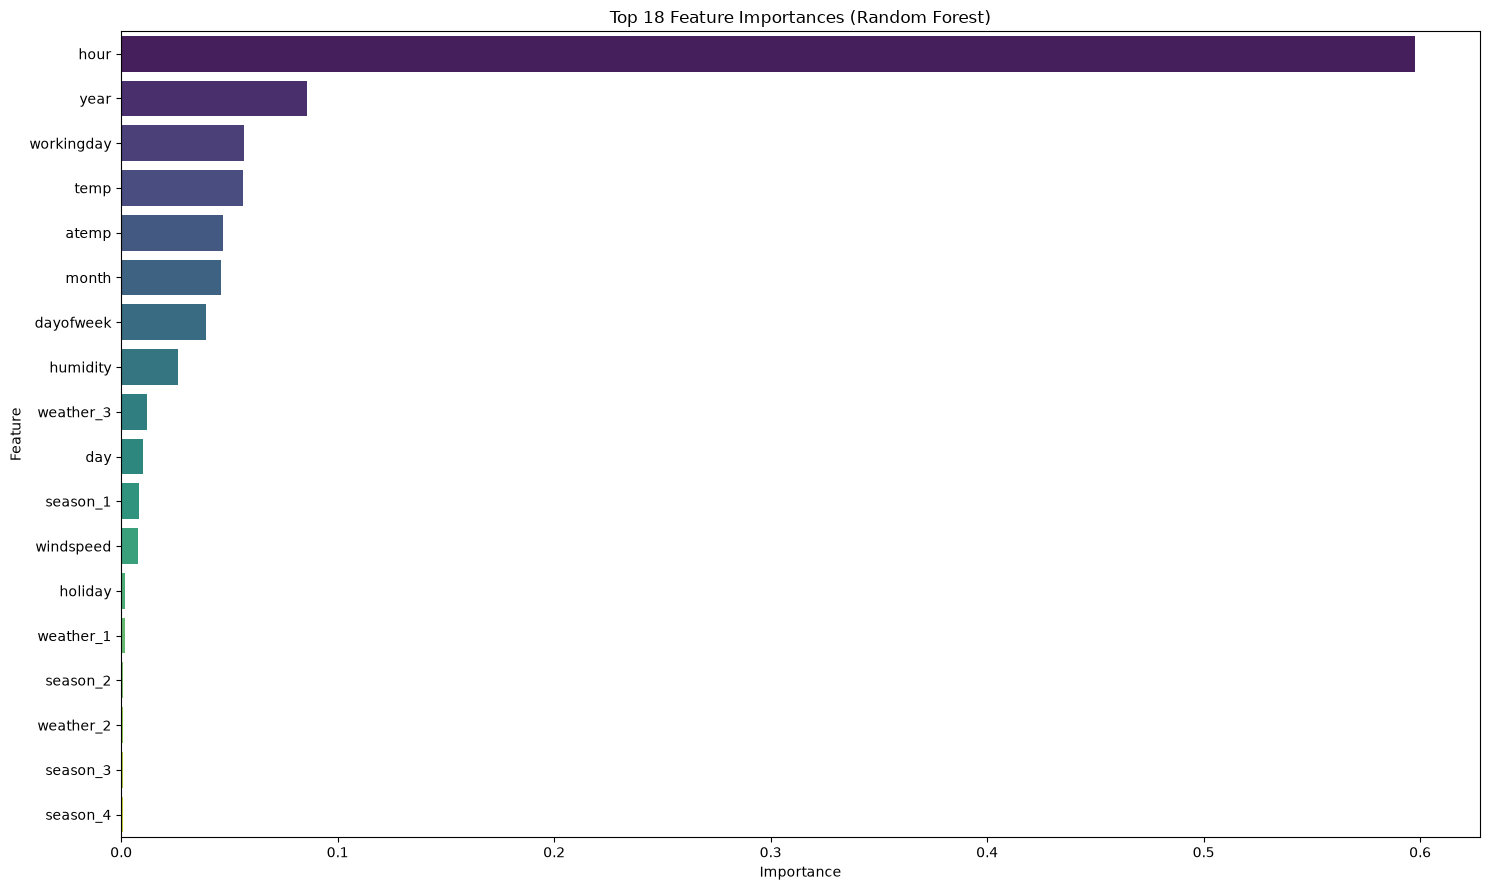

In [39]:
# --- Feature Importance -> Random Forest ---
importances = RF_tuned.feature_importances_

feature_imp = pd.DataFrame({
    'Feature': x_train.columns,
    'Importance': importances
}).sort_values('Importance', ascending=False)

print("Top 18 Most Important Features:")
print(feature_imp.head(18).to_string(index=False))

# --- نمودار ---
plt.figure(figsize=(15, 9))
sns.barplot(
    x='Importance',
    y='Feature',
    data=feature_imp.head(18),
    palette='viridis'
)
plt.title("Top 18 Feature Importances (Random Forest)")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## data preprossing for test set

In [40]:
test_df = pd.read_csv("../data/test.csv")
test_datetime = test_df['datetime'].copy()

test_df['datetime'] = pd.to_datetime(test_df['datetime'])
test_df['year']      = test_df['datetime'].dt.year
test_df['month']     = test_df['datetime'].dt.month
test_df['day']       = test_df['datetime'].dt.day
test_df['hour']      = test_df['datetime'].dt.hour
test_df['dayofweek'] = test_df['datetime'].dt.dayofweek

test_df['weather'] = test_df['weather'].replace({4: 3})
test_df = test_df.drop(columns=['datetime'])

test_df = pd.get_dummies(test_df, columns=['season', 'weather'], drop_first=False)
bool_cols_test = test_df.select_dtypes(include='bool').columns
test_df[bool_cols_test] = test_df[bool_cols_test].astype(int)

test_df = test_df[x_train.columns]

print("Test shape:", test_df.shape)
print("Columns match:", list(test_df.columns) == list(x_train.columns))

Test shape: (6493, 18)
Columns match: True


## final prediction on test set

In [41]:
y_test_pred = RF_tuned.predict(test_df)

print("Predictions shape:", y_test_pred.shape)
print("First 10 predictions:", y_test_pred[:10])
print()
print("Stats:")
print(f"  Min : {y_test_pred.min():.2f}")
print(f"  Max : {y_test_pred.max():.2f}")
print(f"  Mean: {y_test_pred.mean():.2f}")

Predictions shape: (6493,)
First 10 predictions: [ 15.62         6.8          5.35869048   3.62556548   3.06723214
   7.4         35.56        90.85       207.075      118.815     ]

Stats:
  Min : 2.18
  Max : 906.92
  Mean: 193.38


## _______________________________________________________________________________________________

## The End

In [42]:
submission = pd.DataFrame({
    'datetime': test_datetime,
    'count':    y_test_pred.round().astype(int)
})

submission.to_csv("submission_01.csv", index=False)
print("✅ submission_01.csv saved.")
print(submission.head())

✅ submission_01.csv saved.
              datetime  count
0  2011-01-20 00:00:00     16
1  2011-01-20 01:00:00      7
2  2011-01-20 02:00:00      5
3  2011-01-20 03:00:00      4
4  2011-01-20 04:00:00      3


In [43]:
# end check
sample = pd.read_csv("../data/sampleSubmission.csv")

print("Sample shape:", sample.shape)
print("Submission shape:", submission.shape)
print("Same length?", len(sample) == len(submission))
print("Same datetime order?", (sample['datetime'] == submission['datetime']).all())

Sample shape: (6493, 2)
Submission shape: (6493, 2)
Same length? True
Same datetime order? True
